# So sánh 4 loại mô hình PPO trên Ms. Pacman: tiến độ huấn luyện

Mỗi loại mô hình chọn **một run tốt nhất** (tiêu chí: điểm trung bình `LAST_N` ván huấn luyện cuối, xem bảng ở mục 2). Ghi chú quan trọng để đọc biểu đồ:

- LSTM và ViT là **chuỗi train tiếp** (pre 2M -> +1M `step_penalty` 0.05 -> +5M -> +5M). Các giai đoạn được nối lại với bước env cộng dồn, nên đường học dài 13M bước. Ranh giới giữa các giai đoạn đánh dấu bằng `v`. Từ giai đoạn thứ hai, `step_penalty` = 0.05 và lr thấp hơn, nên **không còn cùng điều kiện** với hai CNN.
- Hai CNN chỉ có 1M bước. So sánh công bằng nhất về ngân sách là biểu đồ **1M bước đầu** (mục 4): cùng `death_penalty` 2.5, `step_penalty` 0, 32 env; chỉ khác kiến trúc / đầu vào (ViT dùng lr 1e-4, các mô hình khác 2.5e-4).
- Điểm là **điểm thật của game** (ván đủ 3 mạng), tính trên các ván hoàn thành lúc đang huấn luyện (policy lấy mẫu, còn thay đổi), nên chỉ để xem xu hướng. Đa số chỉ có **1 seed**; chênh lệch dưới ~100–150 điểm không nên coi là khác biệt.
- Notebook chỉ đọc file `.npy` trong `runs/`, không cần GPU. Phần chấm điểm lại (mục 7) tùy chọn, bật bằng `RUN_EVAL`.

## 0. Cấu hình

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RUN_DIR = Path("runs")      # chạy notebook từ thư mục notebooks/
SMOOTH = 200                # cửa sổ trung bình trượt (số ván) cho đường học toàn bộ
SMOOTH_1M = 100             # cửa sổ cho biểu đồ 1M bước đầu
LAST_N = 300                # số ván cuối dùng cho bảng tóm tắt và boxplot
BIN = 500_000               # độ rộng bin (bước) cho biểu đồ sự kiện
RUN_EVAL = False            # True: chấm lại 20 ván/model (mục 7), cần GPU/CPU + emulator
N_EVAL = 20

# Run được chọn cho mỗi loại. Danh sách = chuỗi giai đoạn, nối theo thứ tự (giai đoạn sau train tiếp từ giai đoạn trước).
PICKS = {
    "CNN (xám)": ["pen_const_low_s0"],
    "CNN (RGB)": ["rgb_pen_const_low_s0"],
    "CNN+LSTM": ["lstm_dp25_s0", "lstm_dp25_sp0.05_from_pre_s0",
                 "lstm_dp25_sp0.05_ext5M_s0", "lstm_dp2_sp0.05_plus5M_from_A_s0"],
    "ViT": ["vit_dp25_s0", "vit_dp25_sp0.05_from_pre_s0",
            "vit_dp25_sp0.05_ext5M_s0", "vit_dp2_sp0.05_plus5M_from_A_s0"],
}
COLORS = {"CNN (xám)": "tab:gray", "CNN (RGB)": "tab:green", "CNN+LSTM": "tab:blue", "ViT": "tab:red"}

# Các ứng viên đã xét cho mỗi loại (để mục 2 cho thấy vì sao chọn run trên).
CANDIDATES = {
    "CNN (xám)": {n: [n] for n in ["pen_const_low_s0", "pen_const_low_s1", "pen_curriculum_s0",
                                   "pen_curriculum_s1", "pen_const_high_s0", "pen_const_high_s1"]},
    "CNN (RGB)": {n: [n] for n in ["rgb_pen_const_low_s0", "rgb_pen_const_high_s0", "cnn_rgb_ramp_from_gray_s0"]},
    "CNN+LSTM": {
        "pre -> P1 -> A -> C (+5M, dp 2.5)": PICKS["CNN+LSTM"],
        "pre -> P1 -> A -> B (+1M, dp 10)": ["lstm_dp25_s0", "lstm_dp25_sp0.05_from_pre_s0",
                                             "lstm_dp25_sp0.05_ext5M_s0", "lstm_dp10_sp0.05_from_ext5M_s0"],
        "pre -> P1 -> A": PICKS["CNN+LSTM"][:3],
    },
    "ViT": {
        "pre -> P1 -> A -> C (+5M, dp 2.5)": PICKS["ViT"],
        "pre -> P1 -> A -> B (+1M, dp 10)": ["vit_dp25_s0", "vit_dp25_sp0.05_from_pre_s0",
                                             "vit_dp25_sp0.05_ext5M_s0", "vit_dp10_sp0.05_from_ext5M_s0"],
        "pre -> P1 -> A": PICKS["ViT"][:3],
    },
}
CUM = ("pellets", "ghosts", "deaths")   # các cột log tích lũy trong từng run (reset ở mỗi run)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Hàm đọc dữ liệu và nối các giai đoạn

In [2]:
def load_stage(name):
    ep = np.load(RUN_DIR / f"{name}_episodes.npy")                     # cột 0: bước env, cột 1: điểm thật của ván
    log = np.load(RUN_DIR / f"{name}_log.npy", allow_pickle=True).item()
    return ep.astype(float), {k: np.asarray(v, dtype=float) for k, v in log.items()}


def load_lineage(names):
    """Nối các giai đoạn: bước env cộng dồn, các cột tích lũy (pellets, ghosts, deaths) cộng tiếp từ giá trị cuối của giai đoạn trước."""
    eps, logs, bounds = [], {}, []
    off, base = 0.0, {k: 0.0 for k in CUM}
    for n in names:
        ep, log = load_stage(n)
        eps.append(np.c_[ep[:, 0] + off, ep[:, 1]])
        for k, v in log.items():
            v = v + off if k == "step" else (v + base[k] if k in CUM else v)
            logs.setdefault(k, []).append(v)
        for k in CUM:
            base[k] += log[k][-1]
        off += max(log["step"][-1], ep[-1, 0])
        bounds.append(off)
    return {"names": names, "ep": np.vstack(eps), "log": {k: np.concatenate(v) for k, v in logs.items()},
            "bounds": bounds[:-1], "total": off}


def score_curve(ep, w):
    s = pd.Series(ep[:, 1]).rolling(w, min_periods=max(10, w // 5)).mean().to_numpy()
    return ep[:, 0] / 1e6, s


def per_game(lin, bin_size=BIN):
    """Theo từng bin bước: ma, viên năng lượng, bước sống mỗi ván (chia cho số ván kết thúc trong bin)."""
    s, total, ep = lin["log"]["step"], lin["total"], lin["ep"]
    edges = np.arange(0, total, bin_size)
    edges = np.r_[edges, total] if edges[-1] < total else edges
    games = np.histogram(ep[:, 0], bins=edges)[0].astype(float)
    safe = np.where(games > 0, games, np.nan)
    out = {"x": (edges[:-1] + edges[1:]) / 2e6, "games": games, "steps": np.diff(edges) / safe}
    for k in ("ghosts", "pellets"):
        cum = np.interp(edges, np.r_[0, s], np.r_[0, lin["log"][k]])
        out[k] = np.diff(cum) / safe
    ok = games >= 30                                                    # bỏ bin quá ít ván (bin cuối ngắn)
    return {k: v[ok] for k, v in out.items()}


def summarize(lin, last_n=LAST_N):
    ep, s = lin["ep"], lin["log"]["step"]
    last = ep[-last_n:, 1]
    lo = max(lin["total"] - 1_000_000, 0)
    n_g = max(int((ep[:, 0] >= lo).sum()), 1)                           # số ván trong 1M bước cuối
    ev = {k: (np.interp(lin["total"], np.r_[0, s], np.r_[0, lin["log"][k]])
              - np.interp(lo, np.r_[0, s], np.r_[0, lin["log"][k]])) / n_g for k in ("ghosts", "pellets")}
    return {"tổng bước (M)": lin["total"] / 1e6, "số ván": len(ep),
            f"TB {last_n} ván cuối": last.mean(), "trung vị": np.median(last),
            "phân vị 90": np.percentile(last, 90), "ván cao nhất": ep[:, 1].max(),
            "entropy cuối": lin["log"]["ent"][-10:].mean(),
            "ma/ván (1M cuối)": ev["ghosts"], "viên NL/ván (1M cuối)": ev["pellets"]}

## 2. Vì sao chọn các run này

Bảng liệt kê các ứng viên của từng loại. Cột `TB ... ván cuối` là tiêu chí chọn; dấu `*` đánh dấu run cao nhất trong loại. Lưu ý: ứng viên cùng loại không phải lúc nào cũng cùng ngân sách bước (cột `tổng bước`), và nhiều chênh lệch nằm trong vùng nhiễu.

In [3]:
rows = []
for typ, cands in CANDIDATES.items():
    sub = []
    for label, names in cands.items():
        missing = [n for n in names if not (RUN_DIR / f"{n}_episodes.npy").exists()]
        if missing:
            print(f"bỏ qua {typ} / {label}: thiếu {missing}")
            continue
        s = summarize(load_lineage(names))
        sub.append({"loại": typ, "run": label, "được chọn": names == PICKS[typ], **s})
    best = max(sub, key=lambda r: r[f"TB {LAST_N} ván cuối"])
    for r in sub:
        r["run"] = ("* " if r is best else "  ") + r["run"]
    rows += sub
    if not best["được chọn"]:
        print(f"CẢNH BÁO: {typ}: run cao nhất ({best['run'].strip('* ')}) khác run đang chọn trong PICKS")

cand = pd.DataFrame(rows).set_index(["loại", "run"])
cand.round(2).style.format({"tổng bước (M)": "{:.2f}", f"TB {LAST_N} ván cuối": "{:.0f}", "trung vị": "{:.0f}",
                            "phân vị 90": "{:.0f}", "ván cao nhất": "{:.0f}", "entropy cuối": "{:.2f}",
                            "ma/ván (1M cuối)": "{:.2f}", "viên NL/ván (1M cuối)": "{:.2f}"})

## 3. Tiến độ học: điểm trung bình trượt theo bước env

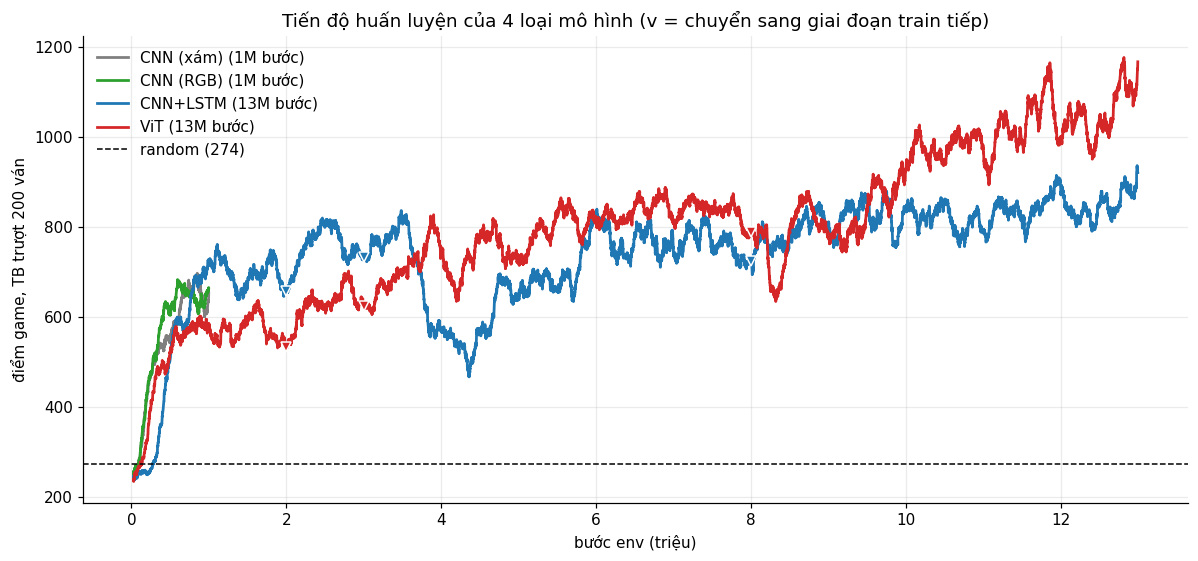

In [4]:
lin = {label: load_lineage(names) for label, names in PICKS.items()}

try:                                    # mốc random (không bắt buộc)
    from pacman_rl import random_baseline
    rnd = float(np.mean(random_baseline(5)))
except Exception as e:
    rnd = None
    print("không tính được random baseline:", type(e).__name__)

fig, ax = plt.subplots(figsize=(11, 5.2))
for label, L in lin.items():
    x, y = score_curve(L["ep"], SMOOTH)
    ax.plot(x, y, color=COLORS[label], lw=1.8, label=f"{label} ({L['total'] / 1e6:.0f}M bước)")
    for b in L["bounds"]:                                        # đánh dấu chỗ chuyển giai đoạn train tiếp
        i = np.searchsorted(L["ep"][:, 0], b)
        ax.plot(b / 1e6, y[min(i, len(y) - 1)], marker="v", color=COLORS[label], ms=7, mec="white")
if rnd is not None:
    ax.axhline(rnd, color="k", ls="--", lw=1, label=f"random ({rnd:.0f})")
ax.set_xlabel("bước env (triệu)")
ax.set_ylabel(f"điểm game, TB trượt {SMOOTH} ván")
ax.set_title("Tiến độ huấn luyện của 4 loại mô hình (v = chuyển sang giai đoạn train tiếp)")
ax.legend(loc="upper left", frameon=False)
fig.tight_layout()
fig.savefig(RUN_DIR / "best_models_learning_curve.png", dpi=150)
plt.show()

## 4. So sánh cùng ngân sách: 1M bước đầu

Cả bốn đều chạy 1M bước đầu với `death_penalty` 2.5, `step_penalty` 0, 32 env x 512 bước (ViT dùng lr 1e-4, còn lại 2.5e-4). Đây là phép so sánh gần với "cùng điều kiện" nhất mà dữ liệu có. Mỗi mô hình 1 seed, nên đọc như xu hướng, không phải kết luận.

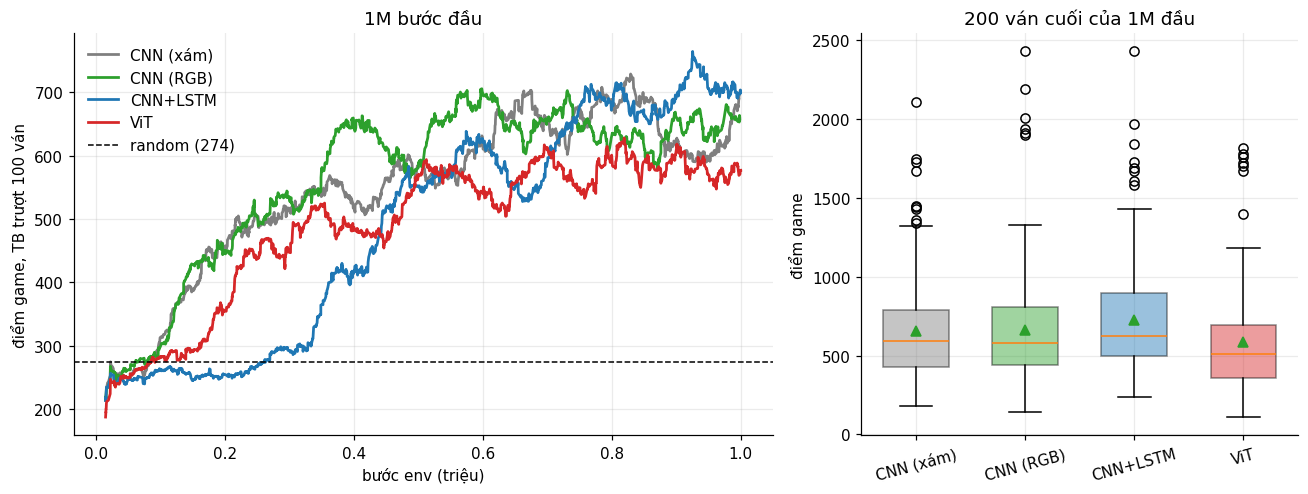

{'CNN (xám)': '653 +- 23 (sai số chuẩn)', 'CNN (RGB)': '665 +- 26 (sai số chuẩn)', 'CNN+LSTM': '723 +- 24 (sai số chuẩn)', 'ViT': '583 +- 22 (sai số chuẩn)'}


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
for label, L in lin.items():
    m = L["ep"][:, 0] <= 1_000_000
    x, y = score_curve(L["ep"][m], SMOOTH_1M)
    ax.plot(x, y, color=COLORS[label], lw=1.8, label=label)
if rnd is not None:
    ax.axhline(rnd, color="k", ls="--", lw=1, label=f"random ({rnd:.0f})")
ax.set_xlabel("bước env (triệu)"); ax.set_ylabel(f"điểm game, TB trượt {SMOOTH_1M} ván")
ax.set_title("1M bước đầu"); ax.legend(frameon=False)

ax = axes[1]
vals = {}
for label, L in lin.items():
    ep = L["ep"][L["ep"][:, 0] <= 1_000_000]
    vals[label] = ep[-200:, 1]                                  # 200 ván cuối của 1M đầu
bp = ax.boxplot(list(vals.values()), labels=list(vals), showmeans=True, patch_artist=True, widths=0.6)
for patch, label in zip(bp["boxes"], vals):
    patch.set_facecolor(COLORS[label]); patch.set_alpha(0.45)
ax.set_title("200 ván cuối của 1M đầu"); ax.set_ylabel("điểm game"); ax.tick_params(axis="x", labelrotation=15)
fig.tight_layout()
fig.savefig(RUN_DIR / "best_models_first_1M.png", dpi=150)
plt.show()
print({k: f"{v.mean():.0f} +- {v.std() / np.sqrt(len(v)):.0f} (sai số chuẩn)" for k, v in vals.items()})

## 5. Hành vi qua các bin: entropy, ma, viên năng lượng, độ sống

`ma/ván` và `viên NL/ván` tính từ cột tích lũy `ghosts`, `pellets` trong log chia cho số ván kết thúc trong bin (đếm theo reward thật; trái cây 200 điểm từ màn 2 có thể bị đếm nhầm là ma). `bước/ván` = số bước sống trung bình của một ván 3 mạng. Entropy tối đa là ln 9 = 2.20.

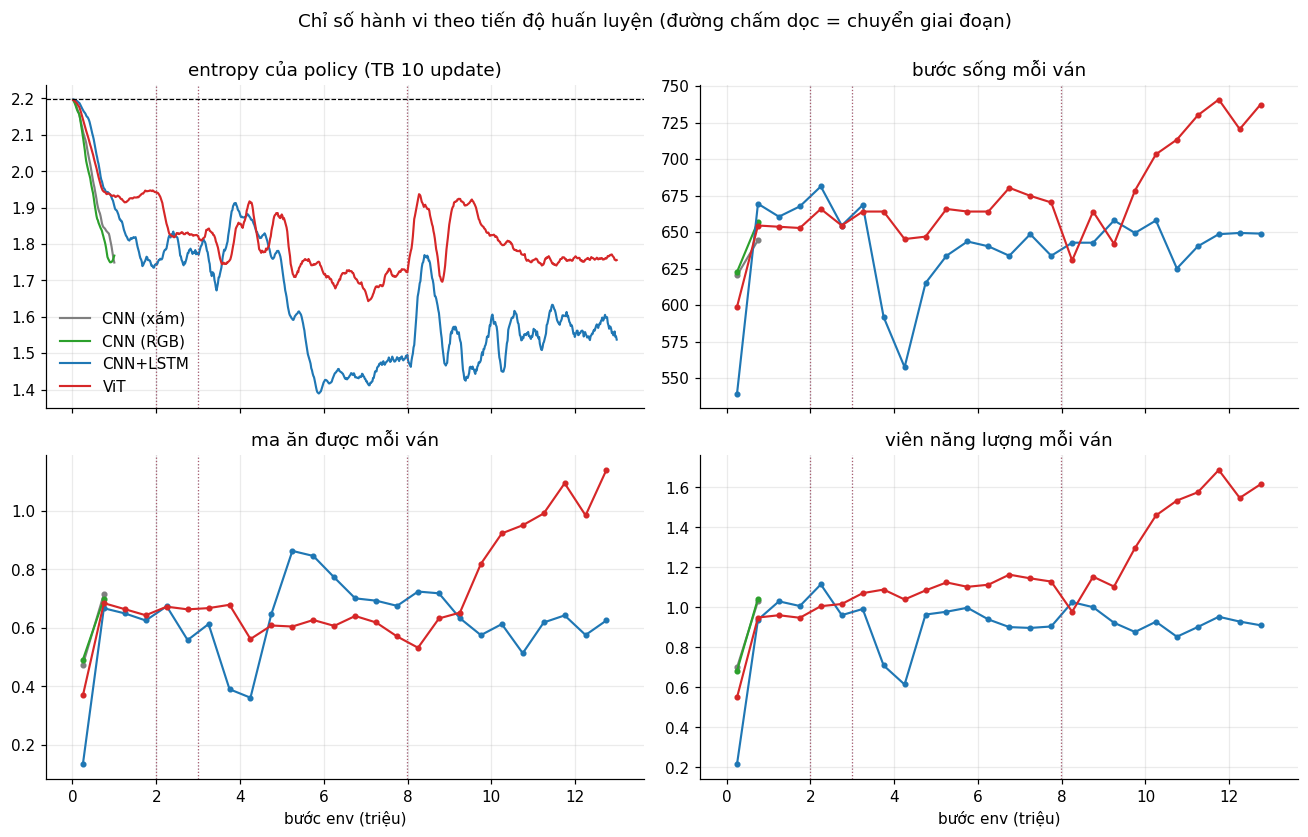

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.6), sharex=True)
for label, L in lin.items():
    c = COLORS[label]
    s = L["log"]
    ent = pd.Series(s["ent"]).rolling(10, min_periods=1).mean().to_numpy()
    axes[0, 0].plot(s["step"] / 1e6, ent, color=c, lw=1.4, label=label)
    pg = per_game(L)
    axes[0, 1].plot(pg["x"], pg["steps"], color=c, marker="o", ms=3, lw=1.4)
    axes[1, 0].plot(pg["x"], pg["ghosts"], color=c, marker="o", ms=3, lw=1.4)
    axes[1, 1].plot(pg["x"], pg["pellets"], color=c, marker="o", ms=3, lw=1.4)
    for ax in axes.ravel():
        for b in L["bounds"]:
            ax.axvline(b / 1e6, color=c, ls=":", lw=0.8, alpha=0.6)
axes[0, 0].set_title("entropy của policy (TB 10 update)"); axes[0, 0].axhline(np.log(9), color="k", ls="--", lw=0.8)
axes[0, 1].set_title("bước sống mỗi ván")
axes[1, 0].set_title("ma ăn được mỗi ván"); axes[1, 1].set_title("viên năng lượng mỗi ván")
for ax in axes[1]:
    ax.set_xlabel("bước env (triệu)")
axes[0, 0].legend(frameon=False, loc="lower left")
fig.suptitle("Chỉ số hành vi theo tiến độ huấn luyện (đường chấm dọc = chuyển giai đoạn)", y=0.995)
fig.tight_layout()
fig.savefig(RUN_DIR / "best_models_behaviour.png", dpi=150)
plt.show()

## 6. Kết quả cuối: phân phối điểm các ván huấn luyện cuối và bảng tóm tắt

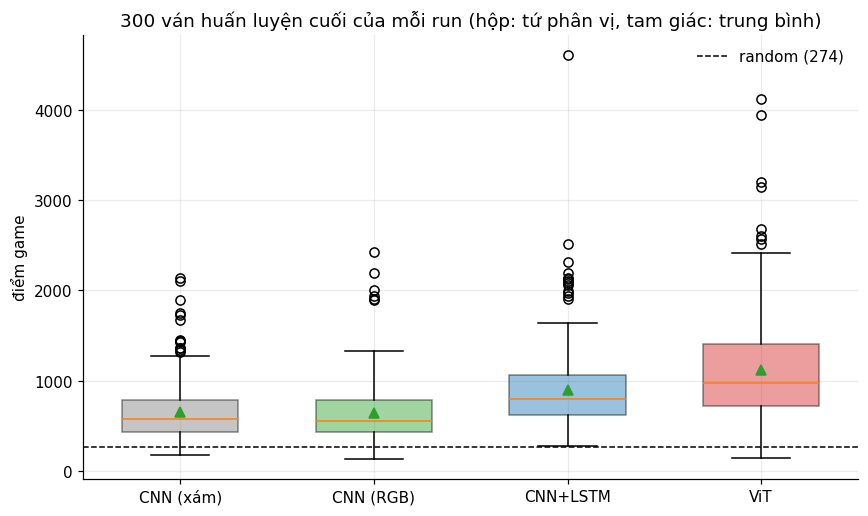

,tổng bước (M),số ván,TB 300 ván cuối,trung vị,phân vị 90,ván cao nhất,entropy cuối,ma/ván (1M cuối),viên NL/ván (1M cuối)
CNN (xám),1.00,1581,652,580,1140,2260,1.75,0.59,0.86
CNN (RGB),1.00,1563,640,560,1070,2460,1.77,0.59,0.86
CNN+LSTM,12.99,20404,900,800,1391,4600,1.54,0.60,0.92
ViT,12.99,19374,1125,975,1940,4720,1.76,1.06,1.58


In [7]:
fig, ax = plt.subplots(figsize=(8, 4.8))
data = [L["ep"][-LAST_N:, 1] for L in lin.values()]
bp = ax.boxplot(data, labels=list(lin), showmeans=True, patch_artist=True, widths=0.6)
for patch, label in zip(bp["boxes"], lin):
    patch.set_facecolor(COLORS[label]); patch.set_alpha(0.45)
if rnd is not None:
    ax.axhline(rnd, color="k", ls="--", lw=1, label=f"random ({rnd:.0f})"); ax.legend(frameon=False)
ax.set_ylabel("điểm game")
ax.set_title(f"{LAST_N} ván huấn luyện cuối của mỗi run (hộp: tứ phân vị, tam giác: trung bình)")
fig.tight_layout()
fig.savefig(RUN_DIR / "best_models_final_box.png", dpi=150)
plt.show()

summary = pd.DataFrame({label: summarize(L) for label, L in lin.items()}).T
summary.round(2).style.format({"tổng bước (M)": "{:.2f}", "số ván": "{:.0f}", f"TB {LAST_N} ván cuối": "{:.0f}",
                               "trung vị": "{:.0f}", "phân vị 90": "{:.0f}", "ván cao nhất": "{:.0f}",
                               "entropy cuối": "{:.2f}", "ma/ván (1M cuối)": "{:.2f}",
                               "viên NL/ván (1M cuối)": "{:.2f}"})

## 7. (Tùy chọn) Chấm điểm lại cùng seed

Đặt `RUN_EVAL = True` ở mục 0 để chấm `N_EVAL` ván (seed 1000, policy lấy mẫu, đủ 3 mạng) cho giai đoạn cuối của mỗi run. **Kết quả này nhiễu**: cùng một model chấm ở hai lần khác nhau từng lệch 100–250 điểm trong các thí nghiệm trước, nên đừng diễn giải chênh lệch nhỏ.

In [8]:
if RUN_EVAL:
    from pacman_rl import get_device
    from pacman_rl.runs import load_run
    from pacman_rl.evaluation import ppo_policy, evaluate
    device = get_device()
    ev = {}
    for label, names in PICKS.items():
        model = load_run(str(RUN_DIR), names[-1], "ppo", device).model.to(device).eval()
        ev[label] = np.asarray(evaluate(ppo_policy(model, device), n_episodes=N_EVAL, seed=1000))
        print(f"{label:10s} TB {ev[label].mean():6.0f} | std {ev[label].std():5.0f} | trung vị {np.median(ev[label]):5.0f} | max {ev[label].max():5.0f}")
    fig, ax = plt.subplots(figsize=(8, 4.6))
    bp = ax.boxplot(list(ev.values()), labels=list(ev), showmeans=True, patch_artist=True, widths=0.6)
    for patch, label in zip(bp["boxes"], ev):
        patch.set_facecolor(COLORS[label]); patch.set_alpha(0.45)
    ax.set_ylabel("điểm game"); ax.set_title(f"Chấm điểm lại {N_EVAL} ván, seed 1000")
    fig.tight_layout(); fig.savefig(RUN_DIR / "best_models_eval_box.png", dpi=150); plt.show()
else:
    print("RUN_EVAL = False: bỏ qua. Đặt True ở mục 0 nếu muốn chấm lại.")

RUN_EVAL = False: bỏ qua. Đặt True ở mục 0 nếu muốn chấm lại.
